In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")


## Step 1 — Load the MathE dataset

In [2]:
data_path = Path("../dataset/MathE dataset (4).csv")

# Fallback if the CSV is placed beside the notebook.
if not data_path.exists():
    data_path = Path("MathE dataset (4).csv")

df = pd.read_csv(
    data_path,
    sep=";",
    encoding="cp1252"
)

df.head()


,Student ID,Student Country,Question ID,Type of Answer,Question Level,Topic,Subtopic,Keywords
0,647,Ireland,77,0,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
1,41,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
2,340,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
3,641,Italy,77,0,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
4,669,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."


## Step 2 — Understand the dataset

In [3]:
print("Shape of dataset:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Shape of dataset: (9546, 8)

Columns:
['Student ID', 'Student Country', 'Question ID', 'Type of Answer', 'Question Level', 'Topic', 'Subtopic', 'Keywords']

Data types:
Student ID         int64
Student Country      str
Question ID        int64
Type of Answer     int64
Question Level       str
Topic                str
Subtopic             str
Keywords             str
dtype: object

Missing values:
Student ID         0
Student Country    0
Question ID        0
Type of Answer     0
Question Level     0
Topic              0
Subtopic           0
Keywords           0
dtype: int64


In [4]:
print("Number of unique students:", df["Student ID"].nunique())

print("\nQuestions attempted per student:")
print(df.groupby("Student ID").size().describe())

print("\nAnswer distribution:")
print(df["Type of Answer"].value_counts())

print("\nQuestion levels:")
print(df["Question Level"].value_counts())

print("\nTop topics:")
print(df["Topic"].value_counts().head(15))


Number of unique students: 372

Questions attempted per student:
count   372.0000
mean     25.6613
std      48.4820
min       1.0000
25%       7.0000
50%      14.0000
75%      29.0000
max     727.0000
dtype: float64

Answer distribution:
Type of Answer
0    5076
1    4470
Name: count, dtype: int64

Question levels:
Question Level
Basic       7844
Advanced    1702
Name: count, dtype: int64

Top topics:
Topic
Linear Algebra                         5726
Fundamental Mathematics                 818
Complex Numbers                         592
Differentiation                         579
Analytic Geometry                       358
Statistics                              340
Numerical Methods                       310
Optimization                            182
Real Functions of a single variable     164
Integration                             144
Probability                             128
Differential Equations                  108
Graph Theory                             55
Set Theory       

## Step 3 — Calculate student-level statistics

In [5]:
student_stats = (
    df.groupby("Student ID")
      .agg(
          total_questions=("Type of Answer", "count"),
          correct_answers=("Type of Answer", "sum")
      )
      .reset_index()
)

student_stats["accuracy"] = (
    student_stats["correct_answers"] /
    student_stats["total_questions"] * 100
)

student_stats.head(10)


,Student ID,total_questions,correct_answers,accuracy
0,26,77,58,75.3247
1,28,59,35,59.3220
2,36,35,18,51.4286
3,37,140,87,62.1429
4,41,59,34,57.6271
5,52,14,5,35.7143
6,57,21,10,47.6190
7,61,16,10,62.5000
8,64,30,13,43.3333
9,67,8,4,50.0000


In [6]:
student_stats["accuracy"].describe()


count   372.0000
mean     45.0378
std      27.4405
min       0.0000
25%      23.9524
50%      43.5417
75%      64.2857
max     100.0000
Name: accuracy, dtype: float64

## Step 4 — Visualize student performance

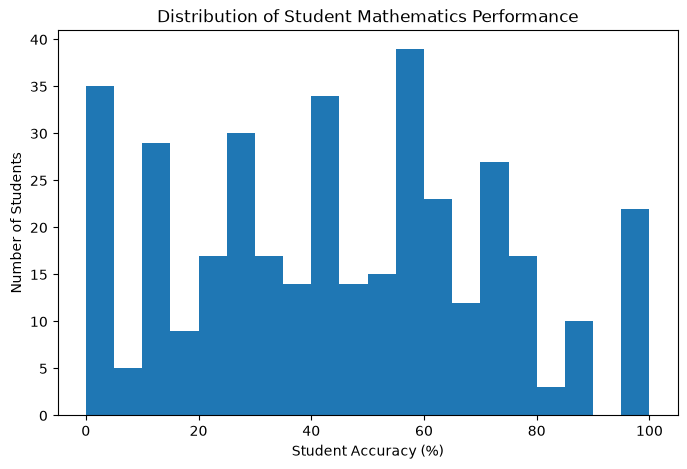

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(student_stats["accuracy"], bins=20)

plt.xlabel("Student Accuracy (%)")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Mathematics Performance")

plt.show()


## Step 5 — Compare Basic vs Advanced performance

In [8]:
level_performance = df.pivot_table(
    index="Student ID",
    columns="Question Level",
    values="Type of Answer",
    aggfunc="mean"
)

level_performance.head(10)


Question Level,Advanced,Basic
Student ID,,
26,NaN,0.7532
28,NaN,0.5932
36,0.5714,0.5000
37,0.8571,0.5952
41,0.6000,0.5741
52,NaN,0.3571
57,NaN,0.4762
61,NaN,0.6250
64,1.0000,0.4138


In [9]:
ml_data = student_stats.copy()

# Align level-wise accuracy using Student ID
level_performance_aligned = level_performance.reindex(
    ml_data["Student ID"]
)

ml_data["basic_accuracy"] = (
    level_performance_aligned["Basic"] * 100
).values

ml_data["advanced_accuracy"] = (
    level_performance_aligned["Advanced"] * 100
).values

ml_data.head(10)


,Student ID,total_questions,correct_answers,accuracy,basic_accuracy,advanced_accuracy
0,26,77,58,75.3247,75.3247,NaN
1,28,59,35,59.3220,59.3220,NaN
2,36,35,18,51.4286,50.0000,57.1429
3,37,140,87,62.1429,59.5238,85.7143
4,41,59,34,57.6271,57.4074,60.0000
5,52,14,5,35.7143,35.7143,NaN
6,57,21,10,47.6190,47.6190,NaN
7,61,16,10,62.5000,62.5000,NaN
8,64,30,13,43.3333,41.3793,100.0000
9,67,8,4,50.0000,50.0000,NaN


### Why these accuracy columns are not used in `X`

`basic_accuracy` and `advanced_accuracy` are useful for **analysis**, but they are not valid predictors of the same student's final `accuracy`.

They are derived from the student's answers, and the final accuracy is also derived from those answers. Feeding them into the model would make the prediction unrealistically easy and would not represent a genuine prediction task.


## Step 6 — Prepare student features

In [10]:
basic_count = (
    df[df["Question Level"] == "Basic"]
    .groupby("Student ID")
    .size()
    .rename("basic_questions")
)

advanced_count = (
    df[df["Question Level"] == "Advanced"]
    .groupby("Student ID")
    .size()
    .rename("advanced_questions")
)

topic_counts = (
    df.groupby("Student ID")["Topic"]
    .nunique()
    .rename("unique_topics")
)

student_country = (
    df.groupby("Student ID")["Student Country"]
    .first()
    .rename("Student Country")
)

ml_data = ml_data.set_index("Student ID")

ml_data["basic_questions"] = ml_data.index.map(basic_count).fillna(0)
ml_data["advanced_questions"] = ml_data.index.map(advanced_count).fillna(0)
ml_data["unique_topics"] = ml_data.index.map(topic_counts).fillna(0)
ml_data["Student Country"] = ml_data.index.map(student_country)

ml_data = ml_data.reset_index()

ml_data.head(10)


,Student ID,total_questions,correct_answers,accuracy,basic_accuracy,advanced_accuracy,basic_questions,advanced_questions,unique_topics,Student Country
0,26,77,58,75.3247,75.3247,NaN,77.0000,0.0000,6,Portugal
1,28,59,35,59.3220,59.3220,NaN,59.0000,0.0000,5,Portugal
2,36,35,18,51.4286,50.0000,57.1429,28.0000,7.0000,3,Portugal
3,37,140,87,62.1429,59.5238,85.7143,126.0000,14.0000,10,Portugal
4,41,59,34,57.6271,57.4074,60.0000,54.0000,5.0000,7,Portugal
5,52,14,5,35.7143,35.7143,NaN,14.0000,0.0000,2,Portugal
6,57,21,10,47.6190,47.6190,NaN,21.0000,0.0000,2,Portugal
7,61,16,10,62.5000,62.5000,NaN,16.0000,0.0000,2,Portugal
8,64,30,13,43.3333,41.3793,100.0000,29.0000,1.0000,5,Portugal
9,67,8,4,50.0000,50.0000,NaN,8.0000,0.0000,2,Portugal


In [11]:
# ---------------------------------------------------------
# Additional behavioral features
# ---------------------------------------------------------

# Total number of questions
ml_data["total_questions"] = (
    ml_data["basic_questions"] + ml_data["advanced_questions"]
)

# Proportion of advanced questions
ml_data["advanced_ratio"] = (
    ml_data["advanced_questions"] /
    ml_data["total_questions"].replace(0, 1)
)

# Proportion of basic questions
ml_data["basic_ratio"] = (
    ml_data["basic_questions"] /
    ml_data["total_questions"].replace(0, 1)
)

ml_data[[
    "Student ID",
    "total_questions",
    "basic_questions",
    "advanced_questions",
    "basic_ratio",
    "advanced_ratio",
    "unique_topics"
]].head(10)

,Student ID,total_questions,basic_questions,advanced_questions,basic_ratio,advanced_ratio,unique_topics
0,26,77.0000,77.0000,0.0000,1.0000,0.0000,6
1,28,59.0000,59.0000,0.0000,1.0000,0.0000,5
2,36,35.0000,28.0000,7.0000,0.8000,0.2000,3
3,37,140.0000,126.0000,14.0000,0.9000,0.1000,10
4,41,59.0000,54.0000,5.0000,0.9153,0.0847,7
5,52,14.0000,14.0000,0.0000,1.0000,0.0000,2
6,57,21.0000,21.0000,0.0000,1.0000,0.0000,2
7,61,16.0000,16.0000,0.0000,1.0000,0.0000,2
8,64,30.0000,29.0000,1.0000,0.9667,0.0333,5
9,67,8.0000,8.0000,0.0000,1.0000,0.0000,2


In [12]:
print("Unique countries:", ml_data["Student Country"].nunique())
print("\nCountries:")
print(sorted(ml_data["Student Country"].dropna().unique().tolist()))

print("\nUnique topics per student:")
print(ml_data["unique_topics"].describe())


Unique countries: 8

Countries:
['Ireland', 'Italy', 'Lithuania', 'Portugal', 'Romania', 'Russian Federation', 'Slovenia', 'Spain']

Unique topics per student:
count   372.0000
mean      1.4812
std       1.1048
min       1.0000
25%       1.0000
50%       1.0000
75%       2.0000
max      10.0000
Name: unique_topics, dtype: float64


### One-hot encode Student Country

In [13]:
ml_data = pd.get_dummies(
    ml_data,
    columns=["Student Country"],
    prefix="country",
    dtype=bool
)

ml_data.head(10)


,Student ID,total_questions,correct_answers,accuracy,basic_accuracy,advanced_accuracy,basic_questions,advanced_questions,unique_topics,advanced_ratio,basic_ratio,country_Ireland,country_Italy,country_Lithuania,country_Portugal,country_Romania,country_Russian Federation,country_Slovenia,country_Spain
0,26,77.0000,58,75.3247,75.3247,NaN,77.0000,0.0000,6,0.0000,1.0000,False,False,False,True,False,False,False,False
1,28,59.0000,35,59.3220,59.3220,NaN,59.0000,0.0000,5,0.0000,1.0000,False,False,False,True,False,False,False,False
2,36,35.0000,18,51.4286,50.0000,57.1429,28.0000,7.0000,3,0.2000,0.8000,False,False,False,True,False,False,False,False
3,37,140.0000,87,62.1429,59.5238,85.7143,126.0000,14.0000,10,0.1000,0.9000,False,False,False,True,False,False,False,False
4,41,59.0000,34,57.6271,57.4074,60.0000,54.0000,5.0000,7,0.0847,0.9153,False,False,False,True,False,False,False,False
5,52,14.0000,5,35.7143,35.7143,NaN,14.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False
6,57,21.0000,10,47.6190,47.6190,NaN,21.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False
7,61,16.0000,10,62.5000,62.5000,NaN,16.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False
8,64,30.0000,13,43.3333,41.3793,100.0000,29.0000,1.0000,5,0.0333,0.9667,False,False,False,True,False,False,False,False
9,67,8.0000,4,50.0000,50.0000,NaN,8.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False


In [14]:
print(ml_data.info())
print("\nMissing values:")
print(ml_data.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 372 entries, 0 to 371
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student ID                  372 non-null    int64  
 1   total_questions             372 non-null    float64
 2   correct_answers             372 non-null    int64  
 3   accuracy                    372 non-null    float64
 4   basic_accuracy              353 non-null    float64
 5   advanced_accuracy           126 non-null    float64
 6   basic_questions             372 non-null    float64
 7   advanced_questions          372 non-null    float64
 8   unique_topics               372 non-null    int64  
 9   advanced_ratio              372 non-null    float64
 10  basic_ratio                 372 non-null    float64
 11  country_Ireland             372 non-null    bool   
 12  country_Italy               372 non-null    bool   
 13  country_Lithuania           372 non-null    bo

## Step 7 — Check the final student-level dataset

In [15]:
print("Final shape:", ml_data.shape)

print("\nFinal columns:")
print(ml_data.columns.tolist())

ml_data.head(10)


Final shape: (372, 19)

Final columns:
['Student ID', 'total_questions', 'correct_answers', 'accuracy', 'basic_accuracy', 'advanced_accuracy', 'basic_questions', 'advanced_questions', 'unique_topics', 'advanced_ratio', 'basic_ratio', 'country_Ireland', 'country_Italy', 'country_Lithuania', 'country_Portugal', 'country_Romania', 'country_Russian Federation', 'country_Slovenia', 'country_Spain']


,Student ID,total_questions,correct_answers,accuracy,basic_accuracy,advanced_accuracy,basic_questions,advanced_questions,unique_topics,advanced_ratio,basic_ratio,country_Ireland,country_Italy,country_Lithuania,country_Portugal,country_Romania,country_Russian Federation,country_Slovenia,country_Spain
0,26,77.0000,58,75.3247,75.3247,NaN,77.0000,0.0000,6,0.0000,1.0000,False,False,False,True,False,False,False,False
1,28,59.0000,35,59.3220,59.3220,NaN,59.0000,0.0000,5,0.0000,1.0000,False,False,False,True,False,False,False,False
2,36,35.0000,18,51.4286,50.0000,57.1429,28.0000,7.0000,3,0.2000,0.8000,False,False,False,True,False,False,False,False
3,37,140.0000,87,62.1429,59.5238,85.7143,126.0000,14.0000,10,0.1000,0.9000,False,False,False,True,False,False,False,False
4,41,59.0000,34,57.6271,57.4074,60.0000,54.0000,5.0000,7,0.0847,0.9153,False,False,False,True,False,False,False,False
5,52,14.0000,5,35.7143,35.7143,NaN,14.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False
6,57,21.0000,10,47.6190,47.6190,NaN,21.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False
7,61,16.0000,10,62.5000,62.5000,NaN,16.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False
8,64,30.0000,13,43.3333,41.3793,100.0000,29.0000,1.0000,5,0.0333,0.9667,False,False,False,True,False,False,False,False
9,67,8.0000,4,50.0000,50.0000,NaN,8.0000,0.0000,2,0.0000,1.0000,False,False,False,True,False,False,False,False


In [16]:
top_topics = df["Topic"].value_counts().head(8).index.tolist()
print(top_topics)

['Linear Algebra', 'Fundamental Mathematics', 'Complex Numbers', 'Differentiation', 'Analytic Geometry', 'Statistics', 'Numerical Methods', 'Optimization']


In [17]:
topic_question_counts = (
    df[df["Topic"].isin(top_topics)]
    .groupby(["Student ID", "Topic"])
    .size()
    .unstack(fill_value=0)
)

topic_question_counts.columns = [
    f"topic_{col.replace(' ', '_')}" for col in topic_question_counts.columns
]

topic_question_counts.head()

,topic_Analytic_Geometry,topic_Complex_Numbers,topic_Differentiation,topic_Fundamental_Mathematics,topic_Linear_Algebra,topic_Numerical_Methods,topic_Optimization,topic_Statistics
Student ID,,,,,,,,
26,27,0,1,0,14,0,0,0
28,36,7,0,0,8,0,0,7
36,0,0,7,0,21,0,0,0
37,7,14,49,7,7,7,14,0
41,12,7,0,14,0,0,0,15


In [18]:
ml_data = ml_data.set_index("Student ID")

# Drop old topic columns if they already exist (safe to re-run)
existing_topic_cols = [c for c in ml_data.columns if c in topic_question_counts.columns]
ml_data = ml_data.drop(columns=existing_topic_cols)

ml_data = ml_data.join(topic_question_counts, how="left")
ml_data[topic_question_counts.columns] = ml_data[topic_question_counts.columns].fillna(0)
ml_data = ml_data.reset_index()

ml_data.head()

,Student ID,total_questions,correct_answers,accuracy,basic_accuracy,advanced_accuracy,basic_questions,advanced_questions,unique_topics,advanced_ratio,basic_ratio,country_Ireland,country_Italy,country_Lithuania,country_Portugal,country_Romania,country_Russian Federation,country_Slovenia,country_Spain,topic_Analytic_Geometry,topic_Complex_Numbers,topic_Differentiation,topic_Fundamental_Mathematics,topic_Linear_Algebra,topic_Numerical_Methods,topic_Optimization,topic_Statistics
0,26,77.0000,58,75.3247,75.3247,NaN,77.0000,0.0000,6,0.0000,1.0000,False,False,False,True,False,False,False,False,27.0000,0.0000,1.0000,0.0000,14.0000,0.0000,0.0000,0.0000
1,28,59.0000,35,59.3220,59.3220,NaN,59.0000,0.0000,5,0.0000,1.0000,False,False,False,True,False,False,False,False,36.0000,7.0000,0.0000,0.0000,8.0000,0.0000,0.0000,7.0000
2,36,35.0000,18,51.4286,50.0000,57.1429,28.0000,7.0000,3,0.2000,0.8000,False,False,False,True,False,False,False,False,0.0000,0.0000,7.0000,0.0000,21.0000,0.0000,0.0000,0.0000
3,37,140.0000,87,62.1429,59.5238,85.7143,126.0000,14.0000,10,0.1000,0.9000,False,False,False,True,False,False,False,False,7.0000,14.0000,49.0000,7.0000,7.0000,7.0000,14.0000,0.0000
4,41,59.0000,34,57.6271,57.4074,60.0000,54.0000,5.0000,7,0.0847,0.9153,False,False,False,True,False,False,False,False,12.0000,7.0000,0.0000,14.0000,0.0000,0.0000,0.0000,15.0000


In [19]:
# ---------------------------------------------------------
# Additional behavioral features
# ---------------------------------------------------------

# Total number of questions
ml_data["total_questions"] = (
    ml_data["basic_questions"] + ml_data["advanced_questions"]
)

# Proportion of advanced questions
ml_data["advanced_ratio"] = (
    ml_data["advanced_questions"] /
    ml_data["total_questions"].replace(0, 1)
)

# Proportion of basic questions
ml_data["basic_ratio"] = (
    ml_data["basic_questions"] /
    ml_data["total_questions"].replace(0, 1)
)

ml_data[[
    "Student ID",
    "total_questions",
    "basic_questions",
    "advanced_questions",
    "basic_ratio",
    "advanced_ratio",
    "unique_topics"
]].head(10)

,Student ID,total_questions,basic_questions,advanced_questions,basic_ratio,advanced_ratio,unique_topics
0,26,77.0000,77.0000,0.0000,1.0000,0.0000,6
1,28,59.0000,59.0000,0.0000,1.0000,0.0000,5
2,36,35.0000,28.0000,7.0000,0.8000,0.2000,3
3,37,140.0000,126.0000,14.0000,0.9000,0.1000,10
4,41,59.0000,54.0000,5.0000,0.9153,0.0847,7
5,52,14.0000,14.0000,0.0000,1.0000,0.0000,2
6,57,21.0000,21.0000,0.0000,1.0000,0.0000,2
7,61,16.0000,16.0000,0.0000,1.0000,0.0000,2
8,64,30.0000,29.0000,1.0000,0.9667,0.0333,5
9,67,8.0000,8.0000,0.0000,1.0000,0.0000,2


## Step 8 — Choose what we want to predict

In [20]:
# ---------------------------------------------------------
# Step 8 — Select ML features and target
# ---------------------------------------------------------

# Raw behavioral features
base_features = [
    "total_questions",
    "basic_ratio",
    "advanced_ratio",
    "unique_topics"
]

# Country features
country_feature_columns = [
    c for c in ml_data.columns
    if c.startswith("country_")
]

# Topic proportion features
topic_ratio_columns = [
    c for c in ml_data.columns
    if c.startswith("topic_") and c.endswith("_ratio")
]

feature_columns = (
    base_features
    + country_feature_columns
    + topic_ratio_columns
)

X = ml_data[feature_columns].copy()
y = ml_data["accuracy"].copy()

print("Number of features:", len(feature_columns))
print("X shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(feature_columns)

Number of features: 12
X shape: (372, 12)
Target shape: (372,)

Features:
['total_questions', 'basic_ratio', 'advanced_ratio', 'unique_topics', 'country_Ireland', 'country_Italy', 'country_Lithuania', 'country_Portugal', 'country_Romania', 'country_Russian Federation', 'country_Slovenia', 'country_Spain']


## Step 9 — Split into training and testing data

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (297, 12)
Testing data: (75, 12)


## Step 10 — Train and evaluate five regression models

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
import numpy as np

def evaluate_model(name, model):

    # Train/test evaluation
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    # 5-fold cross-validation
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_mae = -cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring="neg_mean_absolute_error"
    )

    cv_r2 = cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring="r2"
    )

    print(f"{name}")
    print(f"Test MAE: {mae:.4f}")
    print(f"Test MSE: {mse:.4f}")
    print(f"Test R²: {r2:.4f}")

    print(f"5-Fold CV MAE: {cv_mae.mean():.4f} ± {cv_mae.std():.4f}")
    print(f"5-Fold CV R²: {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
    print()

    return (
        model,
        predictions,
        mae,
        mse,
        r2,
        cv_mae.mean(),
        cv_r2.mean()
    )

In [23]:
from sklearn.linear_model import LinearRegression

linear_model, linear_pred, linear_mae, linear_mse, linear_r2, linear_cv_mae, linear_cv_r2 = evaluate_model(
    "Linear Regression",
    LinearRegression()
)


Linear Regression
Test MAE: 21.5655
Test MSE: 658.1691
Test R²: 0.0547
5-Fold CV MAE: 22.4450 ± 1.2144
5-Fold CV R²: 0.0212 ± 0.0529



In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model, rf_pred, rf_mae, rf_mse, rf_r2, rf_cv_mae, rf_cv_r2 = evaluate_model(
    "Random Forest",
    RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=3
    )
)

Random Forest
Test MAE: 20.0139
Test MSE: 644.9140
Test R²: 0.0738
5-Fold CV MAE: 21.8995 ± 1.2371
5-Fold CV R²: 0.0024 ± 0.0786



In [25]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model, gb_pred, gb_mae, gb_mse, gb_r2, gb_cv_mae, gb_cv_r2 = evaluate_model(
    "Gradient Boosting",
    GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
)

Gradient Boosting
Test MAE: 21.1303
Test MSE: 687.5704
Test R²: 0.0125
5-Fold CV MAE: 22.0060 ± 1.1142
5-Fold CV R²: -0.0176 ± 0.0735



In [26]:
from sklearn.tree import DecisionTreeRegressor

dt_model, dt_pred, dt_mae, dt_mse, dt_r2, dt_cv_mae, dt_cv_r2 = evaluate_model(
    "Decision Tree",
    DecisionTreeRegressor(random_state=42)
)


Decision Tree
Test MAE: 21.5861
Test MSE: 734.4945
Test R²: -0.0549
5-Fold CV MAE: 23.6139 ± 1.4247
5-Fold CV R²: -0.2452 ± 0.1009



In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

svr_model, svr_pred, svr_mae, svr_mse, svr_r2, svr_cv_mae, svr_cv_r2 = evaluate_model(
    "SVR",
    make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf")
    )
)


SVR
Test MAE: 21.3876
Test MSE: 690.1189
Test R²: 0.0088
5-Fold CV MAE: 22.8606 ± 1.2461
5-Fold CV R²: -0.0083 ± 0.0257



## Step 11 — Compare all models

In [28]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "Decision Tree",
        "SVR"
    ],

    "Test MAE": [
        linear_mae,
        rf_mae,
        gb_mae,
        dt_mae,
        svr_mae
    ],

    "Test MSE": [
        linear_mse,
        rf_mse,
        gb_mse,
        dt_mse,
        svr_mse
    ],

    "Test R²": [
        linear_r2,
        rf_r2,
        gb_r2,
        dt_r2,
        svr_r2
    ],

    "CV MAE": [
        linear_cv_mae,
        rf_cv_mae,
        gb_cv_mae,
        dt_cv_mae,
        svr_cv_mae
    ],

    "CV R²": [
        linear_cv_r2,
        rf_cv_r2,
        gb_cv_r2,
        dt_cv_r2,
        svr_cv_r2
    ]
})

results = results.sort_values(
    by="CV MAE"
).reset_index(drop=True)

results

,Model,Test MAE,Test MSE,Test R²,CV MAE,CV R²
0,Random Forest,20.0139,644.9140,0.0738,21.8995,0.0024
1,Gradient Boosting,21.1303,687.5704,0.0125,22.0060,-0.0176
2,Linear Regression,21.5655,658.1691,0.0547,22.4450,0.0212
3,SVR,21.3876,690.1189,0.0088,22.8606,-0.0083
4,Decision Tree,21.5861,734.4945,-0.0549,23.6139,-0.2452


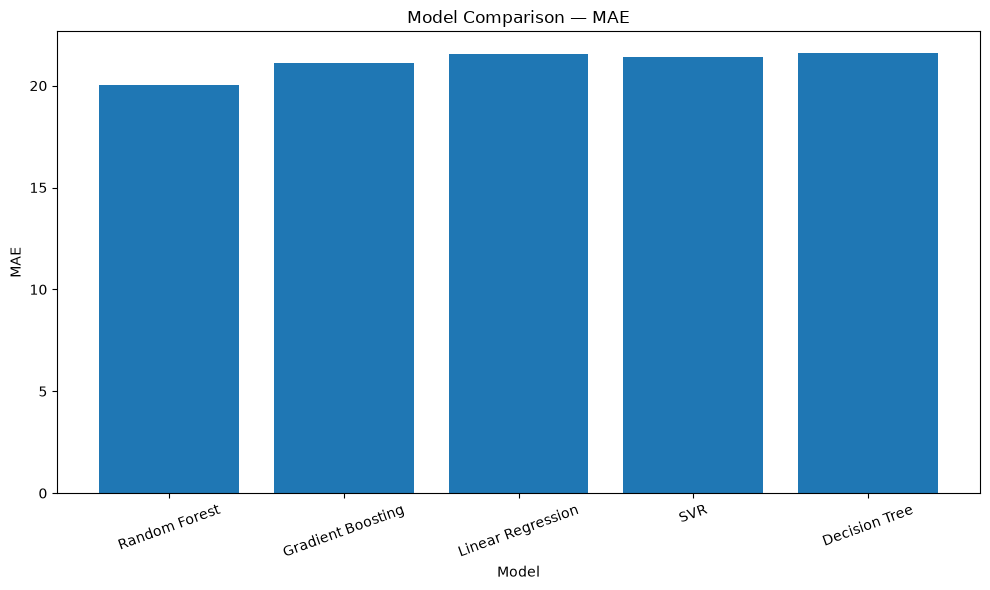

In [29]:
plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["Test MAE"])

plt.xlabel("Model")
plt.ylabel("MAE")
plt.title("Model Comparison — MAE")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

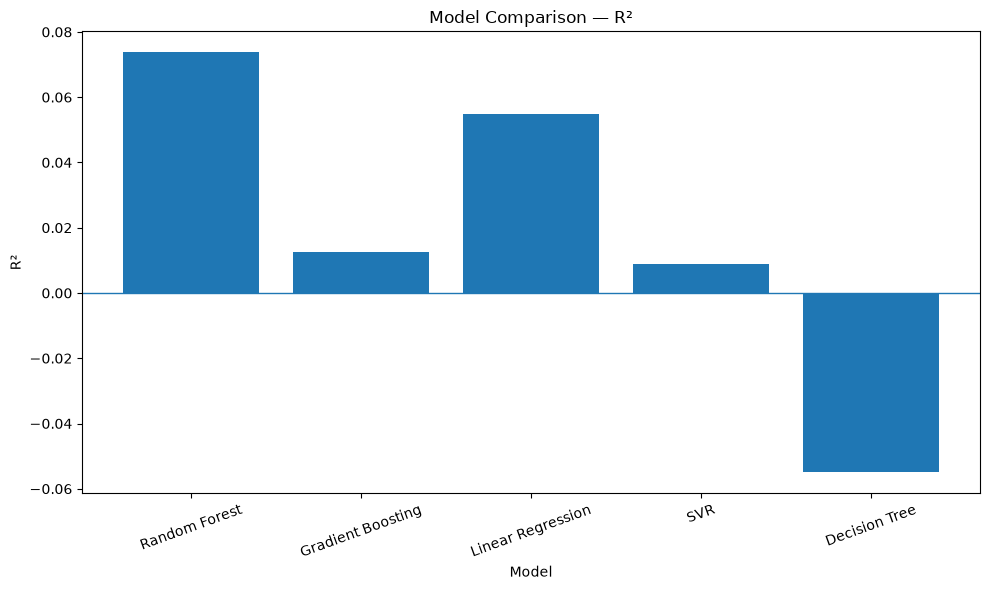

In [30]:
plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["Test R²"])

plt.xlabel("Model")
plt.ylabel("R²")
plt.title("Model Comparison — R²")

plt.xticks(rotation=20)
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()


### Model selection rule

For regression:

- **MAE:** lower is better.
- **MSE:** lower is better.
- **R²:** higher is better; `R² = 0` means the model is roughly no better than predicting the test-set mean, while a negative value means it performs worse than that baseline.

The best model should therefore have low MAE/MSE and the highest R², considered together.


In [31]:
best_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=3
)

best_model.fit(X, y)

print("Final model trained on:", X.shape[0], "students")

Final model trained on: 372 students


## Step 12 — Inspect the Random Forest feature importance

In [32]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

importance


total_questions              0.5464
basic_ratio                  0.1252
advanced_ratio               0.1054
country_Lithuania            0.0810
country_Portugal             0.0565
unique_topics                0.0516
country_Italy                0.0151
country_Ireland              0.0142
country_Slovenia             0.0045
country_Romania              0.0000
country_Russian Federation   0.0000
country_Spain                0.0000
dtype: float64

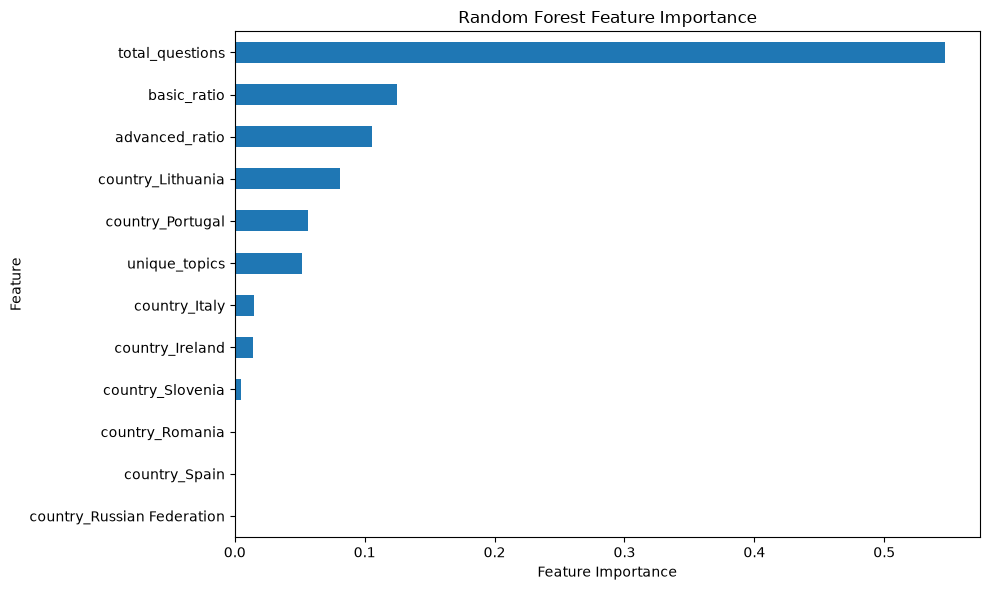

In [33]:
plt.figure(figsize=(10, 6))

importance.sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()


## Step 13 — Retrain the selected model on all available student data

In [34]:
best_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=3
)

best_model.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

## Step 14 — Save the model for Flask

In [35]:
import joblib
import json

model_dir = Path("../model")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "best_model.pkl"
features_path = model_dir / "feature_columns.json"

joblib.dump(best_model, model_path)

with open(features_path, "w", encoding="utf-8") as f:
    json.dump(feature_columns, f, indent=2)

print("Model saved to:", model_path)
print("Feature list saved to:", features_path)


Model saved to: ..\model\best_model.pkl
Feature list saved to: ..\model\feature_columns.json


## Step 15 — Test one deployment-style prediction

In [36]:
sample_student = pd.DataFrame(
    [{col: 0 for col in feature_columns}]
).astype(object)

sample_student.loc[0, "total_questions"] = 60

sample_student.loc[0, "basic_ratio"] = 50 / 60
sample_student.loc[0, "advanced_ratio"] = 10 / 60

sample_student.loc[0, "unique_topics"] = 5

sample_student.loc[0, "country_Portugal"] = True

# Topic proportions
sample_student.loc[0, "topic_Linear_Algebra_ratio"] = 20 / 60
sample_student.loc[0, "topic_Fundamental_Mathematics_ratio"] = 10 / 60
sample_student.loc[0, "topic_Complex_Numbers_ratio"] = 10 / 60
sample_student.loc[0, "topic_Differentiation_ratio"] = 10 / 60
sample_student.loc[0, "topic_Analytic_Geometry_ratio"] = 5 / 60
sample_student.loc[0, "topic_Statistics_ratio"] = 5 / 60

sample_prediction = best_model.predict(
    sample_student[feature_columns]
)[0]

print(f"Predicted student accuracy: {sample_prediction:.2f}%")

Predicted student accuracy: 48.34%


In [37]:
def accuracy_to_label(accuracy_percent):
    if accuracy_percent < 40:
        return "LOW"
    elif accuracy_percent < 70:
        return "MEDIUM"
    else:
        return "HIGH"

# Quick test
print(accuracy_to_label(sample_prediction))

MEDIUM


In [38]:
ml_data["predicted_label"] = ml_data["accuracy"].apply(accuracy_to_label)

print(ml_data["predicted_label"].value_counts())

predicted_label
LOW       156
MEDIUM    137
HIGH       79
Name: count, dtype: int64


In [39]:
import json

thresholds = {
    "low_max": 40,
    "medium_max": 70
}

thresholds_path = model_dir / "thresholds.json"

with open(thresholds_path, "w", encoding="utf-8") as f:
    json.dump(thresholds, f, indent=2)

print("Thresholds saved to:", thresholds_path)

Thresholds saved to: ..\model\thresholds.json


In [40]:
print("=== FINAL CHECK ===")

print("\n1. RESULTS")
print(results)

print("\n2. FEATURES")
print("Number of features:", len(feature_columns))
print(feature_columns)

print("\n3. DATA SHAPE")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\n4. BEST MODEL")
print(best_model)

print("\n5. SAMPLE PREDICTION")
print(f"Predicted accuracy: {sample_prediction:.2f}%")
print(f"Predicted level: {accuracy_to_label(sample_prediction)}")

=== FINAL CHECK ===

1. RESULTS
               Model  Test MAE  Test MSE  Test R²  CV MAE   CV R²
0      Random Forest   20.0139  644.9140   0.0738 21.8995  0.0024
1  Gradient Boosting   21.1303  687.5704   0.0125 22.0060 -0.0176
2  Linear Regression   21.5655  658.1691   0.0547 22.4450  0.0212
3                SVR   21.3876  690.1189   0.0088 22.8606 -0.0083
4      Decision Tree   21.5861  734.4945  -0.0549 23.6139 -0.2452

2. FEATURES
Number of features: 12
['total_questions', 'basic_ratio', 'advanced_ratio', 'unique_topics', 'country_Ireland', 'country_Italy', 'country_Lithuania', 'country_Portugal', 'country_Romania', 'country_Russian Federation', 'country_Slovenia', 'country_Spain']

3. DATA SHAPE
X shape: (372, 12)
y shape: (372,)

4. BEST MODEL
RandomForestRegressor(min_samples_leaf=3, n_estimators=300, random_state=42)

5. SAMPLE PREDICTION
Predicted accuracy: 48.34%
Predicted level: MEDIUM
